=== 1. THÔNG TIN CƠ BẢN ===
Kích thước tập dữ liệu: 5572 dòng, 2 cột

5 dòng đầu tiên:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

=== 2. KIỂM TRA DỮ LIỆU THIẾU & TRÙNG LẶP ===
Số lượng giá trị thiếu (Null):
label      0
message    0
dtype: int64

Số lượng tin nhắn trùng lặp hoàn toàn: 403 (7.23%)

=== 3. PHÂN PHỐI NHÃN (HAM vs SPAM) ===
       Số lượng  Tỷ lệ (%)
label                     
ham        4825      86.59
spam        747      13.41

=== 4. THỐNG KÊ ĐỘ DÀI TIN NHẮN THEO NHÃN ===
      char_length                                                  word_count  \
            count    mean    std   min    25%    50%    75%    max      count   
label                           

C:\Users\Admin\AppData\Local\Temp\ipykernel_6668\3046484280.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', ax=axes[0], palette=['#4C72B0', '#DD8452'])
C:\Users\Admin\AppData\Local\Temp\ipykernel_6668\3046484280.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y='digit_count', ax=axes[2], palette=['#4C72B0', '#DD8452'])


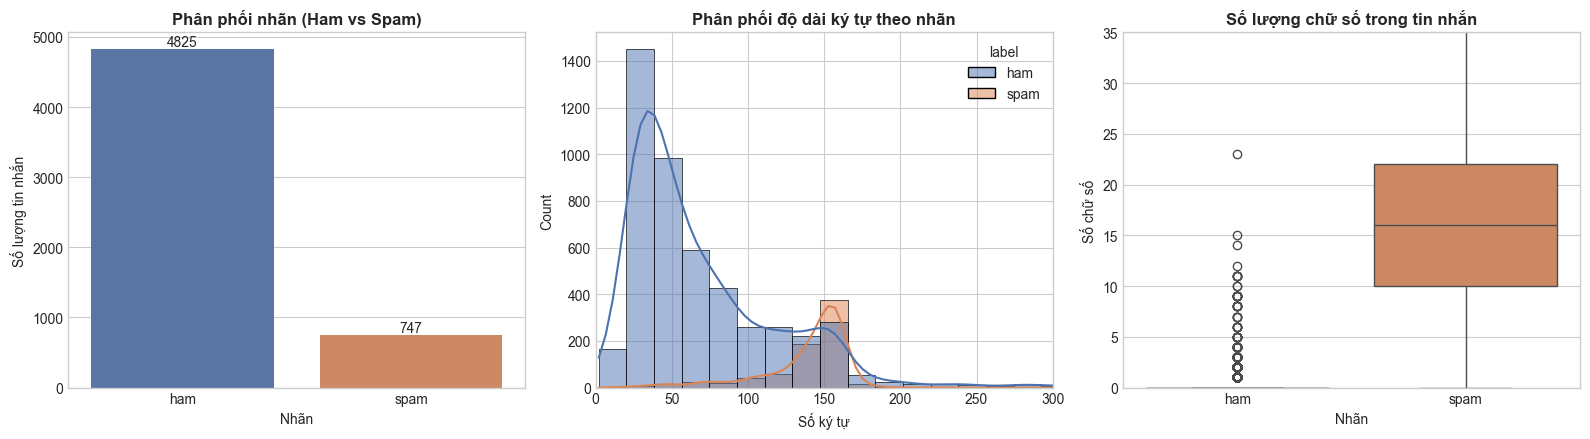

In [6]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Tự động xác định thư mục gốc của dự án (dù chạy từ root hay từ notebooks/)
BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIGURES_DIR = BASE_DIR / 'reports' / 'figures'
DATA_PATH = BASE_DIR / 'data' / 'SMSSpamCollection'

# Tạo thư mục lưu biểu đồ nếu chưa có
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 1. Đọc dữ liệu (file phân tách bằng dấu Tab, không có dòng tiêu đề)
df = pd.read_csv(DATA_PATH, sep='\t', header=None, names=['label', 'message'])

print("=== 1. THÔNG TIN CƠ BẢN ===")
print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")
print("\n5 dòng đầu tiên:")
print(df.head())

print("\n=== 2. KIỂM TRA DỮ LIỆU THIẾU & TRÙNG LẶP ===")
print("Số lượng giá trị thiếu (Null):")
print(df.isnull().sum())

dup_count = df.duplicated().sum()
print(f"\nSố lượng tin nhắn trùng lặp hoàn toàn: {dup_count} ({dup_count/len(df)*100:.2f}%)")

print("\n=== 3. PHÂN PHỐI NHÃN (HAM vs SPAM) ===")
label_counts = df['label'].value_counts()
label_pct = df['label'].value_counts(normalize=True) * 100
summary_label = pd.DataFrame({'Số lượng': label_counts, 'Tỷ lệ (%)': label_pct.round(2)})
print(summary_label)

# 4. Tạo các đặc trưng thống kê phục vụ EDA
df['char_length'] = df['message'].apply(len)
df['word_count'] = df['message'].apply(lambda x: len(x.split()))
df['digit_count'] = df['message'].apply(lambda x: sum(c.isdigit() for c in x))

print("\n=== 4. THỐNG KÊ ĐỘ DÀI TIN NHẮN THEO NHÃN ===")
print(df.groupby('label')[['char_length', 'word_count', 'digit_count']].describe().round(2))

# 5. Trực quan hóa dữ liệu (Lưu ảnh để dùng cho báo cáo)
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Biểu đồ 1: Phân phối nhãn
sns.countplot(data=df, x='label', ax=axes[0], palette=['#4C72B0', '#DD8452'])
axes[0].set_title('Phân phối nhãn (Ham vs Spam)', fontweight='bold')
axes[0].set_xlabel('Nhãn')
axes[0].set_ylabel('Số lượng tin nhắn')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', fontsize=10)

# Biểu đồ 2: Phân phối độ dài ký tự
sns.histplot(data=df, x='char_length', hue='label', bins=50, kde=True, ax=axes[1], palette=['#4C72B0', '#DD8452'])
axes[1].set_title('Phân phối độ dài ký tự theo nhãn', fontweight='bold')
axes[1].set_xlabel('Số ký tự')
axes[1].set_xlim(0, 300)

# Biểu đồ 3: Số lượng chữ số xuất hiện trong tin nhắn
sns.boxplot(data=df, x='label', y='digit_count', ax=axes[2], palette=['#4C72B0', '#DD8452'])
axes[2].set_title('Số lượng chữ số trong tin nhắn', fontweight='bold')
axes[2].set_xlabel('Nhãn')
axes[2].set_ylabel('Số chữ số')
axes[2].set_ylim(0, 35)

plt.tight_layout()
plt.savefig('../reports/figures/eda_overview.png', dpi=300)
plt.show()


In [7]:
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 1. Loại bỏ dữ liệu trùng lặp để tránh Data Leakage giữa Train và Test
df_clean = df.drop_duplicates(subset=['message']).copy()
print(f"Số lượng mẫu sau khi loại bỏ trùng lặp: {len(df_clean)} (đã xóa {len(df) - len(df_clean)} mẫu trùng)")
print("Phân phối nhãn sau khi làm sạch:")
print(df_clean['label'].value_counts())

# 2. Mã hóa nhãn mục tiêu: ham = 0, spam = 1
df_clean['target'] = df_clean['label'].map({'ham': 0, 'spam': 1})

# 3. Chia tập Train (80%) và Test (20%) có phân tầng (stratify) và cố định random_state
X = df_clean['message']
y = df_clean['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nKích thước tập Train: {len(X_train)} mẫu | Tập Test: {len(X_test)} mẫu")

# 4. Định nghĩa 2 hàm tiền xử lý văn bản để so sánh
def preprocess_basic(text):
    """Phương án 1 (Cơ bản): Chuyển chữ thường, xóa toàn bộ số và ký tự đặc biệt."""
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)  # Xóa số và dấu câu
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def preprocess_sms_optimized(text):
    """Phương án 2 (Cải tiến cho SMS): Giữ lại tín hiệu đặc thù của Spam dưới dạng token."""
    text = text.lower()
    # Chuẩn hóa URL/Website
    text = re.sub(r'(http\S+|www\.\S+|\S+\.(com|co\.uk|net|org)\S*)', ' token_url ', text)
    # Chuẩn hóa đơn vị tiền tệ (£, $, € hoặc số kèm gbp/usd)
    text = re.sub(r'([£$€]\s*\d+([.,]\d+)?|\d+([.,]\d+)?\s*(gbp|usd|pound|pounds))', ' token_money ', text)
    # Chuẩn hóa chuỗi số (số điện thoại, mã tổng đài, mã thưởng)
    text = re.sub(r'\d+', ' token_num ', text)
    # Giữ tín hiệu dấu chấm than / dấu hỏi
    text = re.sub(r'!+', ' token_exclam ', text)
    # Xóa các dấu câu còn lại
    text = re.sub(r'[^a-z0-9_\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Áp dụng tiền xử lý (chỉ biến đổi độc lập từng câu nên không gây rò rỉ dữ liệu)
X_train_basic = X_train.apply(preprocess_basic)
X_test_basic = X_test.apply(preprocess_basic)

X_train_opt = X_train.apply(preprocess_sms_optimized)
X_test_opt = X_test.apply(preprocess_sms_optimized)

print("\n=== VÍ DỤ SO SÁNH TIỀN XỬ LÝ ===")
sample_spam = df_clean[df_clean['label'] == 'spam']['message'].iloc[0]
print("Gốc       :", sample_spam)
print("Cơ bản    :", preprocess_basic(sample_spam))
print("Cải tiến  :", preprocess_sms_optimized(sample_spam))

# 5. Vector hóa (CHỈ FIT TRÊN TẬP TRAIN ĐỂ CHỐNG DATA LEAKAGE)
# Bộ đặc trưng A: Tiền xử lý cơ bản + Bag-of-Words (Unigram)
bow_vec = CountVectorizer(ngram_range=(1, 1))
X_train_bow = bow_vec.fit_transform(X_train_basic)
X_test_bow = bow_vec.transform(X_test_basic)

# Bộ đặc trưng B: Tiền xử lý cải tiến + TF-IDF (Unigram + Bigram, min_df=2)
tfidf_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95)
X_train_tfidf = tfidf_vec.fit_transform(X_train_opt)
X_test_tfidf = tfidf_vec.transform(X_test_opt)

print(f"\nSố lượng đặc trưng (từ vựng) - Phương án 1 (BOW cơ bản)     : {X_train_bow.shape[1]}")
print(f"Số lượng đặc trưng (từ vựng) - Phương án 2 (TF-IDF cải tiến): {X_train_tfidf.shape[1]}")

Số lượng mẫu sau khi loại bỏ trùng lặp: 5169 (đã xóa 403 mẫu trùng)
Phân phối nhãn sau khi làm sạch:
label
ham     4516
spam     653
Name: count, dtype: int64

Kích thước tập Train: 4135 mẫu | Tập Test: 1034 mẫu

=== VÍ DỤ SO SÁNH TIỀN XỬ LÝ ===
Gốc       : Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Cơ bản    : free entry in a wkly comp to win fa cup final tkts st may text fa to to receive entry question std txt rate t c s apply over s
Cải tiến  : free entry in token_num a wkly comp to win fa cup final tkts token_num st may token_num text fa to token_num to receive entry question std txt rate t c s apply token_num over token_num s

Số lượng đặc trưng (từ vựng) - Phương án 1 (BOW cơ bản)     : 6862
Số lượng đặc trưng (từ vựng) - Phương án 2 (TF-IDF cải tiến): 10167


=== BẢNG SO SÁNH KẾT QUẢ CÁC THÍ NGHIỆM ===
                                       Thí nghiệm  Accuracy (%)  Precision Spam (%)  Recall Spam (%)  F1-score Spam (%)  Thời gian train (s)
       1. [Baseline] MNB (alpha=1.0) + BOW cơ bản         98.07               93.70            90.84              92.25               0.0050
     2. Decision Tree (max_depth=20) + BOW cơ bản         96.71               90.08            83.21              86.51               0.1230
               3. K-NN (k=5, cosine) + BOW cơ bản         97.00               95.45            80.15              87.14               0.0010
             4. MNB (alpha=1.0) + TF-IDF cải tiến         97.39              100.00            79.39              88.51               0.0020
       5. MNB (tuned alpha=0.2) + TF-IDF cải tiến         98.84              100.00            90.84              95.20               0.0020
6. Decision Tree (max_depth=20) + TF-IDF cải tiến         97.49               92.68            87.02          

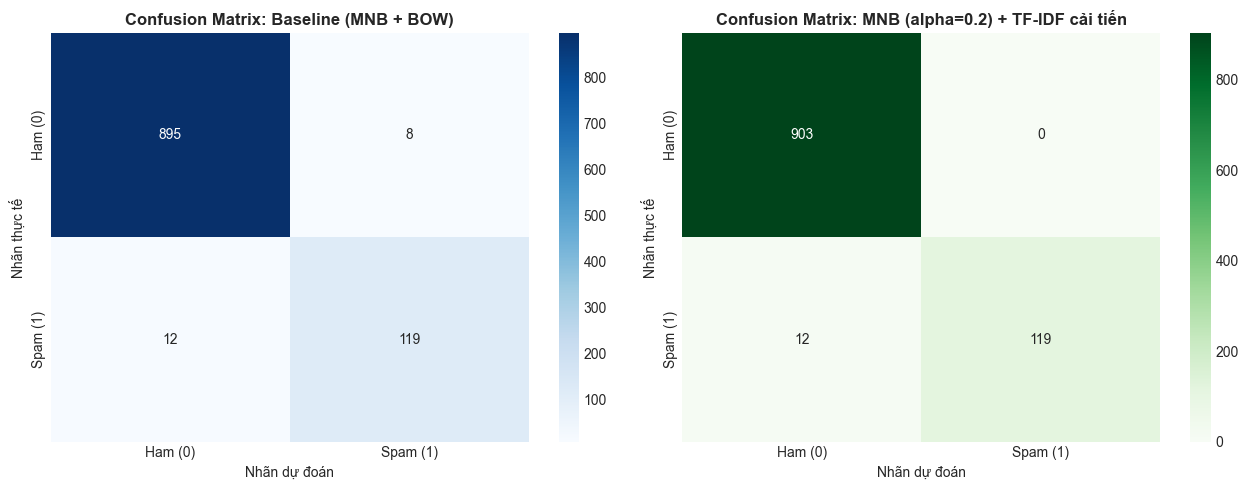

In [9]:
import time
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Hàm đánh giá và lưu kết quả từng thí nghiệm
results = []
trained_models = {}

def evaluate_experiment(exp_name, model, X_tr, y_tr, X_te, y_te):
    start_time = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - start_time
    
    y_pred = model.predict(X_te)
    
    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred) # Mặc định pos_label=1 (spam)
    rec = recall_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred)
    
    results.append({
        'Thí nghiệm': exp_name,
        'Accuracy (%)': round(acc * 100, 2),
        'Precision Spam (%)': round(prec * 100, 2),
        'Recall Spam (%)': round(rec * 100, 2),
        'F1-score Spam (%)': round(f1 * 100, 2),
        'Thời gian train (s)': round(train_time, 4)
    })
    trained_models[exp_name] = (model, y_pred)
    return y_pred

# --- NHÓM THÍ NGHIỆM 1: TRÊN BỘ ĐẶC TRƯNG CƠ BẢN (BOW Unigram) ---
# 1. Baseline: Multinomial Naive Bayes mặc định
evaluate_experiment(
    "1. [Baseline] MNB (alpha=1.0) + BOW cơ bản",
    MultinomialNB(alpha=1.0), X_train_bow, y_train, X_test_bow, y_test
)
# 2. Decision Tree trên BOW cơ bản
evaluate_experiment(
    "2. Decision Tree (max_depth=20) + BOW cơ bản",
    DecisionTreeClassifier(max_depth=20, random_state=42), X_train_bow, y_train, X_test_bow, y_test
)
# 3. K-NN trên BOW cơ bản
evaluate_experiment(
    "3. K-NN (k=5, cosine) + BOW cơ bản",
    KNeighborsClassifier(n_neighbors=5, metric='cosine'), X_train_bow, y_train, X_test_bow, y_test
)

# --- NHÓM THÍ NGHIỆM 2: TRÊN BỘ ĐẶC TRƯNG CẢI TIẾN (TF-IDF + Token hóa SMS) ---
# 4. Multinomial Naive Bayes mặc định + TF-IDF cải tiến
evaluate_experiment(
    "4. MNB (alpha=1.0) + TF-IDF cải tiến",
    MultinomialNB(alpha=1.0), X_train_tfidf, y_train, X_test_tfidf, y_test
)
# 5. Multinomial Naive Bayes tinh chỉnh alpha=0.2 + TF-IDF cải tiến
evaluate_experiment(
    "5. MNB (tuned alpha=0.2) + TF-IDF cải tiến",
    MultinomialNB(alpha=0.2), X_train_tfidf, y_train, X_test_tfidf, y_test
)
# 6. Decision Tree + TF-IDF cải tiến
evaluate_experiment(
    "6. Decision Tree (max_depth=20) + TF-IDF cải tiến",
    DecisionTreeClassifier(max_depth=20, random_state=42), X_train_tfidf, y_train, X_test_tfidf, y_test
)
# 7. K-NN + TF-IDF cải tiến
evaluate_experiment(
    "7. K-NN (k=5, cosine) + TF-IDF cải tiến",
    KNeighborsClassifier(n_neighbors=5, metric='cosine'), X_train_tfidf, y_train, X_test_tfidf, y_test
)

# Hiển thị bảng tổng hợp kết quả
df_results = pd.DataFrame(results)
print("=== BẢNG SO SÁNH KẾT QUẢ CÁC THÍ NGHIỆM ===")
print(df_results.to_string(index=False))

# Vẽ biểu đồ so sánh F1-score và Confusion Matrix cho Baseline vs Mô hình tốt nhất
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_base = confusion_matrix(y_test, trained_models["1. [Baseline] MNB (alpha=1.0) + BOW cơ bản"][1])
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Ham (0)', 'Spam (1)'], yticklabels=['Ham (0)', 'Spam (1)'])
axes[0].set_title('Confusion Matrix: Baseline (MNB + BOW)', fontweight='bold')
axes[0].set_xlabel('Nhãn dự đoán')
axes[0].set_ylabel('Nhãn thực tế')

cm_best = confusion_matrix(y_test, trained_models["5. MNB (tuned alpha=0.2) + TF-IDF cải tiến"][1])
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Ham (0)', 'Spam (1)'], yticklabels=['Ham (0)', 'Spam (1)'])
axes[1].set_title('Confusion Matrix: MNB (alpha=0.2) + TF-IDF cải tiến', fontweight='bold')
axes[1].set_xlabel('Nhãn dự đoán')
axes[1].set_ylabel('Nhãn thực tế')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'confusion_matrices.png', dpi=300)
plt.show()

In [10]:
# 1. Phân tích lỗi (Error Analysis) trên mô hình tốt nhất (Thí nghiệm 5)
y_pred_best = trained_models["5. MNB (tuned alpha=0.2) + TF-IDF cải tiến"][1]
y_pred_base = trained_models["1. [Baseline] MNB (alpha=1.0) + BOW cơ bản"][1]

df_test_analysis = pd.DataFrame({
    'message': X_test.values,
    'clean_opt': X_test_opt.values,
    'actual': y_test.values,
    'pred_base': y_pred_base,
    'pred_best': y_pred_best
})

# Các trường hợp False Negatives (Thực tế là Spam = 1, nhưng mô hình tốt nhất đoán nhầm là Ham = 0)
fn_cases = df_test_analysis[(df_test_analysis['actual'] == 1) & (df_test_analysis['pred_best'] == 0)]
print(f"=== 1. CÁC TIN NHẮN SPAM BỊ LỌT QUA (FALSE NEGATIVES - {len(fn_cases)} MẪU) ===")
for idx, row in fn_cases.iterrows():
    print(f"- [Gốc]: {row['message']}")
    print(f"  [Sau xử lý]: {row['clean_opt']}\n")

# Các trường hợp Baseline bắt nhầm Ham thành Spam (FP), nhưng mô hình cải tiến đã khắc phục được
fixed_fp_cases = df_test_analysis[
    (df_test_analysis['actual'] == 0) &
    (df_test_analysis['pred_base'] == 1) &
    (df_test_analysis['pred_best'] == 0)
]
print(f"=== 2. CÁC TIN NHẮN HAM ĐƯỢC CỨU KHỎI BẮT NHẦM NHỜ CẢI TIẾN ({len(fixed_fp_cases)} MẪU) ===")
for idx, row in fixed_fp_cases.head(5).iterrows():
    print(f"- {row['message']}")

# 2. Diễn giải mô hình: Top 15 đặc trưng (từ/bigram/token) có trọng số xác suất Spam cao nhất
best_mnb = trained_models["5. MNB (tuned alpha=0.2) + TF-IDF cải tiến"][0]
feature_names = np.array(tfidf_vec.get_feature_names_out())

# Tính chênh lệch log-probability giữa lớp Spam (1) và lớp Ham (0)
spam_log_prob_diff = best_mnb.feature_log_prob_[1] - best_mnb.feature_log_prob_[0]
top_spam_indices = np.argsort(spam_log_prob_diff)[::-1][:15]

print("\n=== 3. TOP 15 ĐẶC TRƯNG NHẬN DIỆN SPAM MẠNH NHẤT ===")
for rank, idx in enumerate(top_spam_indices, 1):
    print(f"{rank:2d}. {feature_names[idx]:<20} (Log-odds ratio: {spam_log_prob_diff[idx]:.2f})")

=== 1. CÁC TIN NHẮN SPAM BỊ LỌT QUA (FALSE NEGATIVES - 12 MẪU) ===
- [Gốc]: ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT. BAILIFF DUE IN DAYS. I O £250 3 WANT £800
  [Sau xử lý]: asked token_num mobile if token_num chatlines inclu in free mins india cust servs sed yes l token_num er got mega bill token_num dont giv a shit bailiff due in days i o token_money token_num want token_money

- [Gốc]: Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 09099726395 Lucy x Calls£1/minMobsmoreLKPOBOX177HP51FL
  [Sau xử lý]: hi its lucy hubby at meetins all day fri i will b alone at hotel u fancy cumin over pls leave msg token_num day token_num lucy x calls token_money minmobsmorelkpobox token_num hp token_num fl

- [Gốc]: Missed call alert. These numbers called but left no message. 07008009200
  [Sau xử lý]: missed call alert these numbers called but left no message token_n

In [11]:
import joblib

MODELS_DIR = BASE_DIR / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Lưu bộ vector hóa TF-IDF và mô hình Multinomial Naive Bayes tốt nhất (alpha=0.2)
joblib.dump(tfidf_vec, MODELS_DIR / 'tfidf_vectorizer.joblib')
joblib.dump(best_mnb, MODELS_DIR / 'mnb_spam_classifier.joblib')

print("Đã lưu thành công bộ vector hóa và mô hình vào thư mục models/!")

Đã lưu thành công bộ vector hóa và mô hình vào thư mục models/!
